# Pre-Processing

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv('Salary.csv')

In [7]:
df.isnull().sum()

YearsExperience    1
Salary             1
dtype: int64

In [8]:
df.isnull().sum().sum()

np.int64(2)

In [9]:
df.dropna(inplace=True)

In [10]:
df.isnull().sum()

YearsExperience    0
Salary             0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(2)

In [12]:
df = df.drop_duplicates()

In [13]:
df.duplicated().sum()

np.int64(0)

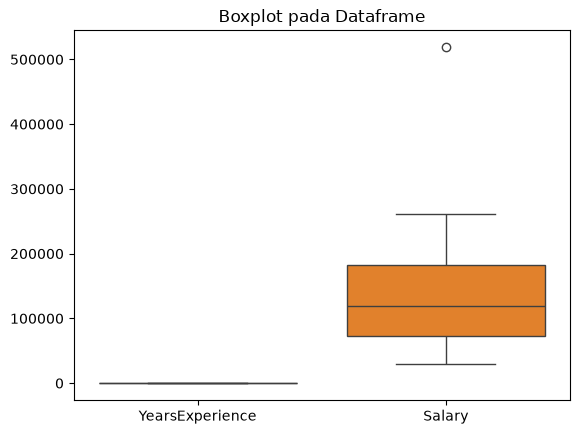

In [14]:
sns.boxplot(data=df)
plt.title('Boxplot pada Dataframe')
plt.show()

In [15]:
Q1 = df['Salary'].quantile(0.25)
Q3 = df['Salary'].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outliers = ((df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas)).sum()
print("Jumlah outlier pada kolom Salary:", outliers)

Jumlah outlier pada kolom Salary: 1


In [16]:
df[(df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas)]


,YearsExperience,Salary
59,17.0,518900.0


In [17]:
df = df[~((df['Salary'] < batas_bawah) | (df['Salary'] > batas_atas))]

In [18]:
z_score = (df['Salary'] - df['Salary'].mean()) / df['Salary'].std()

outlier = (np.abs(z_score) > 3)

print("Jumlah outlier di kolom Salary: ", outlier.sum())

print("-" * 35)

df_outlier = df[outlier]
print(df_outlier)

Jumlah outlier di kolom Salary:  0
-----------------------------------
Empty DataFrame
Columns: [YearsExperience, Salary]
Index: []


In [19]:
corr_kendall = df.corr(method='kendall')
corr_kendall

,YearsExperience,Salary
YearsExperience,1.000000,0.943767
Salary,0.943767,1.000000


In [20]:
corr_spearman = df.corr(method='spearman')
corr_spearman

,YearsExperience,Salary
YearsExperience,1.000000,0.993966
Salary,0.993966,1.000000


In [21]:
corr_pearson = df.corr(method='pearson')
corr_pearson

,YearsExperience,Salary
YearsExperience,1.000000,0.987997
Salary,0.987997,1.000000


<Axes: title={'center': 'Heatmap dengan method spearman'}>

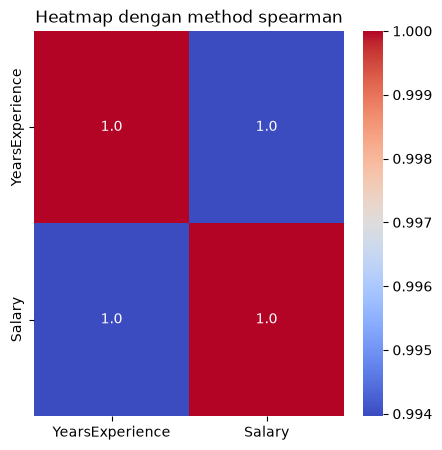

In [22]:
plt.figure(figsize=(5, 5))
plt.title('Heatmap dengan method spearman')
sns.heatmap(corr_spearman, annot=True, cmap='coolwarm', fmt='.1f')

<Axes: xlabel='YearsExperience', ylabel='Salary'>

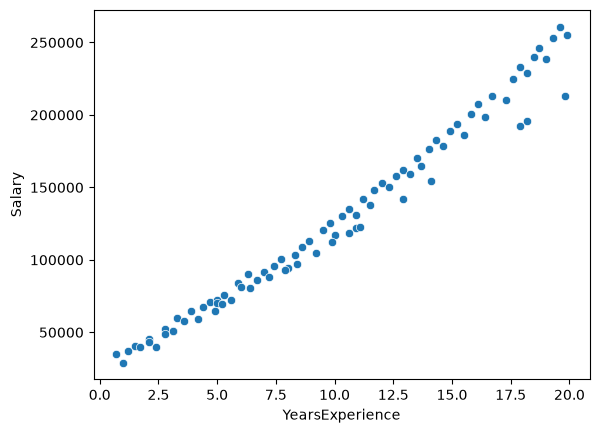

In [23]:
sns.scatterplot(data=df, x='YearsExperience', y='Salary')

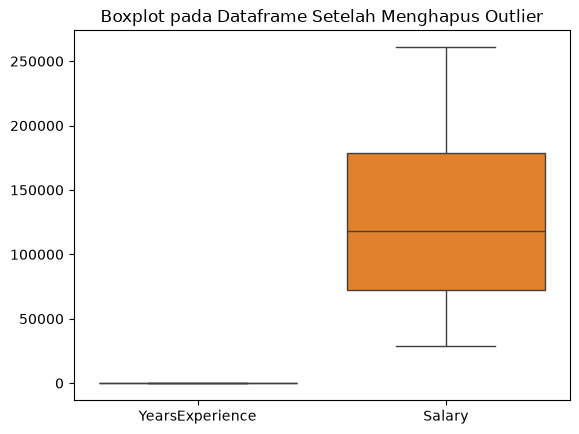

In [24]:
sns.boxplot(data=df)
plt.title('Boxplot pada Dataframe Setelah Menghapus Outlier')
plt.show()

In [25]:
rata_rata = np.mean(df, axis=0)
simpangan = np.std(df, axis=0)

data_standarisasi = (df - rata_rata) / simpangan
print("Data setelah standarisasi:")
print(data_standarisasi)

Data setelah standarisasi:
    YearsExperience    Salary
0         -1.680736 -1.447598
1         -1.590385 -1.414533
2         -1.626525 -1.541262
3         -1.536175 -1.361409
4         -1.427754 -1.287913
..              ...       ...
85        -1.500034 -1.366110
86         0.523822  0.228869
87         0.108208 -0.143952
88        -0.289335 -0.472723
89         1.770661  1.340580

[85 rows x 2 columns]


In [26]:
def split_data(x, y, train_size=0.8, random_state=42):
  np.random.seed(random_state)
  idx = np.random.permutation(len(x))
  split_ratio = int(train_size * len(x))
  
  x_train, x_text = x.iloc[idx[:split_ratio]], x.iloc[idx[split_ratio:]]
  y_train, y_text = y.iloc[idx[:split_ratio]], y.iloc[idx[split_ratio:]]
  
  return x_train, x_text, y_train, y_text

In [27]:
x_train, x_test, y_train, y_test = split_data(df[['YearsExperience']], df['Salary'], train_size=0.8, random_state=42)

In [28]:
slope = np.sum((df['YearsExperience'] - np.mean(df['YearsExperience'])) * (df['Salary'] - np.mean(df['Salary']))) / np.sum((df['YearsExperience'] - np.mean(df['YearsExperience']))**2)

In [29]:
intercept = np.mean(df['Salary'] - slope * np.mean(df['YearsExperience']))

In [31]:
y_pred = slope * x_test + intercept
y_pred

,YearsExperience
62,217375.395162
66,229907.420553
78,69269.640539
38,141043.967779
30,114840.641961
1,27116.464223
54,190032.794309
21,89776.591179
2,24837.914152
23,95472.966357


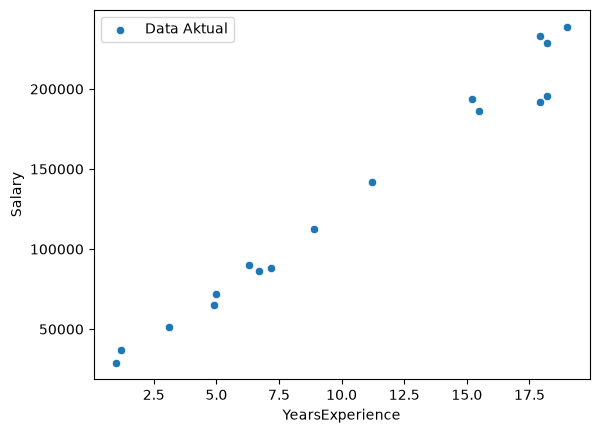

In [35]:
sns.scatterplot(x=x_test['YearsExperience'], y=y_test, label='Data Aktual')
plt.show()